# 01 - Train water / tree: how much of our own (Mae Suai) data do we need?
- **Train on:** all OpenEarthMap (OEM) images + **0% / 25% / 50% / 75% / 100%** of our Mae Suai images (these are the **seen** images).
- **Test on:** the Mae Suai images **not** used for training (the **unseen** share): 0% -> 100% unseen, 25% -> 75% unseen, 50% -> 50% unseen. At 100% nothing is unseen, so the score is measured on the training images (fit only, not generalization).
- Image and mask are matched by **same file name** (`1.tif` image <-> `1.tif` mask in `own_paired`; notebook 01 section 2 makes this folder).
- All settings (classes, model, training) come from `configs/water_tree.yaml`. To switch model, change `model.active` there.
- The code lives in `src/` (data, models, training, plots). This notebook only sets the options, runs the training and draws the results.

## 1. Setup

In [2]:
%load_ext autoreload
%autoreload 2

import os, sys, json
import torch
import pandas as pd
REPO_DIR = r"C:\land_cover_senior2026"
os.chdir(REPO_DIR); sys.path.insert(0, REPO_DIR)

from src.train import load_config
from src.data.paths import resolve_paths
from src.data.pairing import pair_folder, shuffle_pairs, split_for
from src.data.seg_dataset import get_oem_ids
from src.experiments.fraction import run_fraction
from src.visualization.plots import print_table, plot_miou, plot_confusions, plot_iou_heatmap

cfg = load_config("configs/water_tree.yaml")
# cfg["model"]["active"] = "fpn_r50"      # <- uncomment to switch model without editing the yaml

# ---- the option you can change ----
FRACTIONS = [0.0, 0.25, 0.5, 0.75, 1.0]         # share of ALL Mae Suai images used (seen) in training; the rest is unseen test

P = resolve_paths(cfg)
CLASSES    = cfg["classes"]
MODEL_NAME = cfg["model"]["active"]
SEED       = cfg["train"]["seed"]
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device, "| model:", MODEL_NAME, "|", cfg["models"][MODEL_NAME], "| classes:", CLASSES)

Device: cuda | model: unet_r34 | {'decoder': 'unet', 'encoder': 'resnet34', 'encoder_weights': 'imagenet'} | classes: ['other', 'tree', 'water']


## 2. Pair images with masks and make the fixed split
Images and masks are matched by the same file name. All Mae Suai images are shuffled once (seed in the yaml) and saved to `results/own_split.json`.
For a fraction `f`, the first `f` of the shuffled list is **seen** (training) and the rest is **unseen** (test). So the 25% images are always inside the 50% images, and those inside the 100% images.

In [2]:
own_pairs = pair_folder(P["own_images"], P["own_masks"])
oem_pairs = pair_folder(P["oem_images"], P["oem_masks"])
print("Mae Suai pairs:", len(own_pairs), "| OEM pairs:", len(oem_pairs))
assert len(own_pairs) > 0, "No Mae Suai pairs - run notebook 01 section 2 first"

own_shuffled = shuffle_pairs(own_pairs, SEED)
json.dump({"order": [a.stem for a, _ in own_shuffled]}, open(P["results_dir"] / "own_split.json", "w"), indent=2)

total = len(own_shuffled)
for f in FRACTIONS:
    seen, unseen = split_for(own_shuffled, f)
    note = "  (no unseen images left -> tested on seen images)" if f >= 1.0 else ""
    print(f"  {int(f*100):3d}% -> seen (train) {round(f*total):3d} | unseen (test) {total - round(f*total):3d}{note}")

OWN_IDS = cfg["mask_ids"]["own"]
OEM_IDS, oem_seen = get_oem_ids(cfg, oem_pairs)
print("own mask ids:", OWN_IDS)
print("oem mask ids:", OEM_IDS, "| values seen in OEM labels:", sorted(oem_seen) if oem_seen else "n/a")

Mae Suai pairs: 31 | OEM pairs: 356
    0% -> seen (train)   0 | unseen (test)  31
   25% -> seen (train)   8 | unseen (test)  23
   50% -> seen (train)  16 | unseen (test)  15
  100% -> seen (train)  31 | unseen (test)   0  (no unseen images left -> tested on seen images)
own mask ids: {'tree': [5], 'water': [6], 'ignore': [0, 9]}
oem mask ids: {'tree': [4], 'water': [5], 'ignore': [0]} | values seen in OEM labels: [0, 1, 2, 3, 4, 5, 6, 7]


## 3. Train (one model per option)
This trains one model per option, so it takes a while. Change `FRACTIONS` in section 1 to run fewer.
Same recipe as `train.py` (cross-entropy + Dice, Adam, mixed precision). The score reported is from the **last epoch**, so we do not pick the best epoch using the test images.

In [3]:
results = []
for f in FRACTIONS:
    results.append(run_fraction(f, cfg, device, oem_pairs, own_shuffled, OEM_IDS, OWN_IDS, P["weights_dir"]))
    json.dump(results, open(P["results_dir"] / f"own_fraction_{MODEL_NAME}_results.json", "w"), indent=2)


=== unet_r34 | 0% ===
Images trained on: 356 OEM + 0 Mae Suai = 356 unique images
Samples per epoch (Mae Suai x5 repeat): 356
Test on 31 unseen Mae Suai images
epoch  1 | train_loss 1.576 | test mIoU 0.298
epoch  2 | train_loss 1.212 | test mIoU 0.342
epoch  3 | train_loss 1.093 | test mIoU 0.057
epoch  4 | train_loss 0.989 | test mIoU 0.346
epoch  5 | train_loss 0.940 | test mIoU 0.353
epoch  6 | train_loss 0.890 | test mIoU 0.252
epoch  7 | train_loss 0.860 | test mIoU 0.303
epoch  8 | train_loss 0.870 | test mIoU 0.101
epoch  9 | train_loss 0.814 | test mIoU 0.043
epoch 10 | train_loss 0.850 | test mIoU 0.247
epoch 11 | train_loss 0.752 | test mIoU 0.259
epoch 12 | train_loss 0.777 | test mIoU 0.258
epoch 13 | train_loss 0.724 | test mIoU 0.162
epoch 14 | train_loss 0.781 | test mIoU 0.271
epoch 15 | train_loss 0.710 | test mIoU 0.290
epoch 16 | train_loss 0.735 | test mIoU 0.323
epoch 17 | train_loss 0.734 | test mIoU 0.094
epoch 18 | train_loss 0.725 | test mIoU 0.039
epoch 19 | 

## 4. Results (each option is tested on the Mae Suai images it did not see; 100% is tested on its own training images)

In [3]:
# Convert results to a DataFrame to inspect the new columns
df_results = pd.DataFrame(results)

# Display model, encoder, decoder, time, and mIoU side-by-side
display(df_results[["model", "encoder", "decoder", "fraction", "train_time_min", "mIoU"]])

NameError: name 'results' is not defined

Mae Suai in training   test imgs   mIoU   other    tree   water
  0% (0 imgs)                 31  0.027   0.050   0.031   0.000
 25% (8 imgs)                 23  0.519   0.163   0.923   0.470
 50% (16 imgs)                15  0.473   0.065   0.892   0.461
100% (31 imgs)                31  0.743   0.711   0.956   0.560


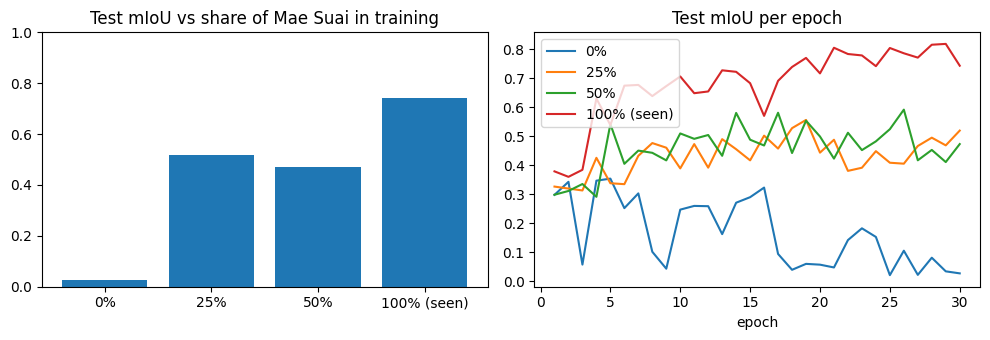

In [4]:
print_table(results, CLASSES)
plot_miou(results, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_miou.png")

## 5. Heatmaps: where did it go wrong?
- **Confusion matrices** (one per option): each row is the true class, each column is what the model predicted. Numbers are the % of that true class, so the diagonal is correct and every off-diagonal cell is a specific mistake (e.g. true *tree* predicted as *other*).
- **IoU + mIoU heatmap**: one row per option, one column per class and the overall mIoU, for a side-by-side comparison.

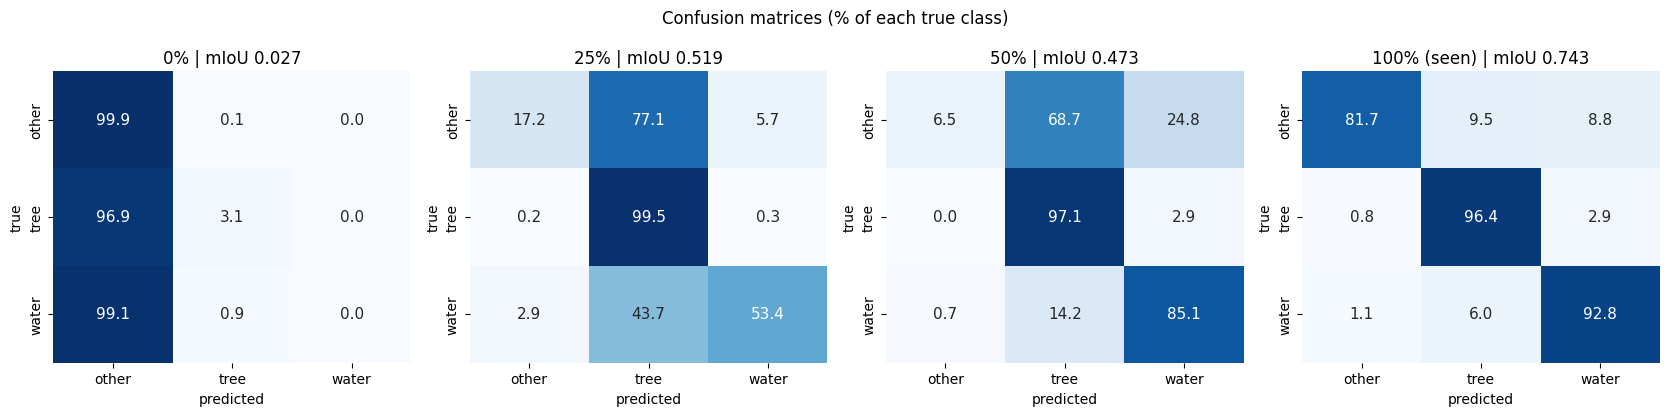

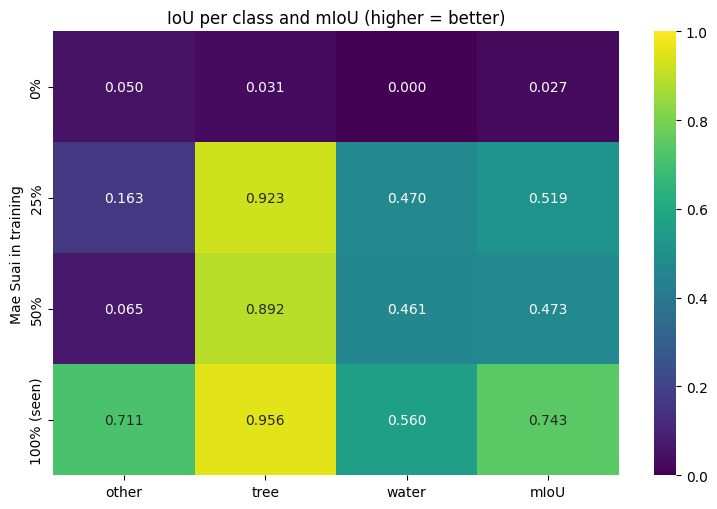

In [5]:
plot_confusions(results, CLASSES, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_confusion.png")
plot_iou_heatmap(results, CLASSES, save_to=P["results_dir"] / f"own_fraction_{MODEL_NAME}_iou_heatmap.png")

## Notes
- Each option has a **different test set** (0% tests on all images, 25% on 75%, 50% on 50%), so the scores are not measured on identical images. Small differences can be noise.
- The 100% option has no unseen images, so its score only shows how well the model fits its training data. Do not read it as generalization.
- The split order is listed in `results/own_split.json`. Weights and results files include the model name, so different models do not overwrite each other.
- Before committing to GitHub: *Kernel > Restart & Clear Output*.